# Max-Cut QUBO on a D-Wave Quantum Computer

This notebook solves the same weighted Max-Cut instance as **MaxCut-QUBO-BruteForce.ipynb**, but submits the QUBO to a real D-Wave quantum processing unit (QPU) through Ocean.

The Solver API token is read from the environment variable **DWAVE_API_TOKEN**. It is never placed in the notebook or printed.

## 1. Install Ocean and visualization packages

Run this once for the selected notebook kernel.

In [1]:
%pip install -q "dwave-ocean-sdk>=9.0,<10" "networkx>=3.2,<4" "matplotlib>=3.8,<4"

Note: you may need to restart the kernel to use updated packages.


## 2. Use the same weighted graph as the brute-force notebook

A negative edge weight is allowed in this signed, weighted example. Maximizing the cut prefers positive-weight edges to be cut and negative-weight edges to remain uncut.

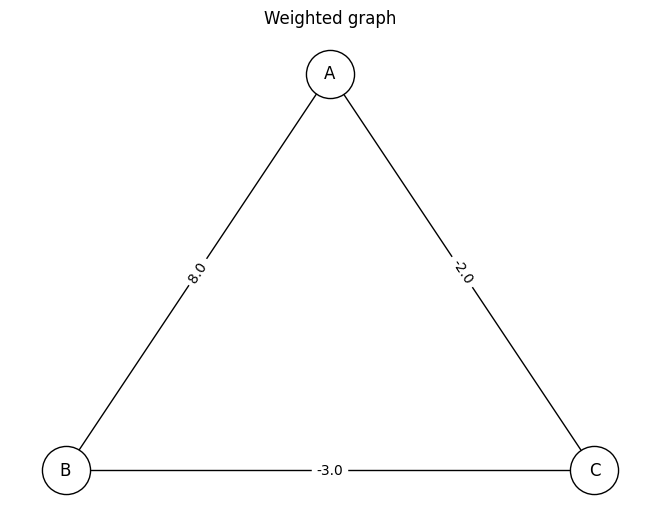

In [2]:
import os
from collections import defaultdict

import dimod
import matplotlib.pyplot as plt
import networkx as nx
from dwave.system import DWaveSampler, EmbeddingComposite, LeapHybridSampler

edge_dict = {
    ("A", "B"): 8.0,
    ("A", "C"): -2.0,
    ("B", "C"): -3.0,
}

graph = nx.Graph()
for (u, v), weight in edge_dict.items():
    graph.add_edge(u, v, weight=weight)

positions = {"A": (0.5, 1.0), "B": (0, 0), "C": (1, 0)}
nx.draw(graph, positions, with_labels=True, node_color="white",
        edgecolors="black", node_size=1200)
nx.draw_networkx_edge_labels(
    graph, positions, edge_labels=nx.get_edge_attributes(graph, "weight")
)
plt.title("Weighted graph")
plt.show()

## 3. Formulate Max-Cut as an Ocean QUBO

Let each binary variable indicate a vertex partition. For edge $(u,v)$ with weight $w$, the cut contribution is

$$w(x_u+x_v-2x_ux_v).$$

D-Wave minimizes energy, so the edge contributes

$$-wx_u-wx_v+2wx_ux_v.$$

Ocean's QUBO dictionary stores one coefficient per unordered interaction. Therefore each edge adds $-w$ to both diagonal terms and $2w$ to the single interaction term.

In [3]:
Q = defaultdict(float)

for (u, v), weight in edge_dict.items():
    Q[(u, u)] -= weight
    Q[(v, v)] -= weight
    Q[(u, v)] += 2.0 * weight

Q = dict(Q)
bqm = dimod.BinaryQuadraticModel.from_qubo(Q)

print("Ocean QUBO dictionary:")
for variables, bias in sorted(Q.items()):
    print(f"  {variables}: {bias:+g}")

Ocean QUBO dictionary:
  ('A', 'A'): -6
  ('A', 'B'): +16
  ('A', 'C'): -4
  ('B', 'B'): -5
  ('B', 'C'): -6
  ('C', 'C'): +5


### Matrix convention warning

The brute-force notebook uses a symmetric matrix in $x^TQx$. Thus entries $Q_{ij}$ and $Q_{ji}$ both contribute to the same product $x_ix_j$. Ocean's dictionary includes the pair only once. For example, the brute-force matrix has 8 in both AB positions, while the Ocean dictionary has one AB interaction of 16. These represent the same polynomial.

## 4. Local exact check before using QPU time

For three variables, checking all eight states is inexpensive. This confirms the formulation and provides the exact reference answer. It does not use the QPU.

In [4]:
exact_sampleset = dimod.ExactSolver().sample(bqm)
exact_best = exact_sampleset.first
exact_solution = {v: int(side) for v, side in exact_best.sample.items()}

print(exact_sampleset)
print("Exact optimum:", exact_solution)
print("Exact QUBO energy:", exact_best.energy)
print("Exact maximum cut weight:", -exact_best.energy)

   A  B  C energy num_oc.
1  1  0  0   -6.0       1
4  0  1  1   -6.0       1
3  0  1  0   -5.0       1
6  1  0  1   -5.0       1
0  0  0  0    0.0       1
5  1  1  1    0.0       1
2  1  1  0    5.0       1
7  0  0  1    5.0       1
['BINARY', 8 rows, 8 samples, 3 variables]
Exact optimum: {'A': 1, 'B': 0, 'C': 0}
Exact QUBO energy: -6.0
Exact maximum cut weight: 6.0


## 5. Configure the API token

Set the token before starting Jupyter. On macOS or Linux:

    export DWAVE_API_TOKEN="your-solver-api-token"
    jupyter lab

On Windows PowerShell:

    $env:DWAVE_API_TOKEN = "your-solver-api-token"
    jupyter lab

Restart the notebook kernel after changing the environment. Never commit a real token to source control.

In [5]:
token_is_configured = bool(os.getenv("DWAVE_API_TOKEN"))
print("DWAVE_API_TOKEN configured:", token_is_configured)

if not token_is_configured:
    print("Set DWAVE_API_TOKEN, restart the kernel, and rerun this cell before submission.")

DWAVE_API_TOKEN configured: True


## 6. Submit directly to an Advantage QPU

**This cell consumes remote QPU access time.** The `pegasus` topology filter explicitly selects an Advantage-generation QPU (Advantage2 uses `zephyr`). `EmbeddingComposite` maps the three logical variables and their interactions onto physical qubits and couplers. Multiple reads are useful because quantum annealing is probabilistic and can return different states.

In [6]:
if not os.getenv("DWAVE_API_TOKEN"):
    raise RuntimeError("DWAVE_API_TOKEN is not configured; QPU submission was not attempted.")

# Pegasus topology means an Advantage QPU, rather than Advantage2 (Zephyr).
qpu = DWaveSampler(solver={"topology__type": "pegasus"})
qpu_name = qpu.solver.name

with EmbeddingComposite(qpu) as quantum_sampler:
    qpu_sampleset = quantum_sampler.sample(
        bqm,
        num_reads=100,
        label="MaxCut QUBO Ocean tutorial",
        return_embedding=True,
    )

print("QPU:", qpu_name)
print(qpu_sampleset.aggregate())

QPU: Advantage_system4
   B  A  C energy num_oc. chain_.
0  0  1  0   -6.0      29     0.0
1  1  0  1   -6.0      55     0.0
2  1  0  0   -5.0       6     0.0
3  0  1  1   -5.0      10     0.0
['BINARY', 4 rows, 100 samples, 3 variables]


## 7. Decode and validate the QPU answer

In [7]:
qpu_best = qpu_sampleset.first
qpu_solution = {v: int(side) for v, side in qpu_best.sample.items()}
partition_0 = sorted(v for v, side in qpu_solution.items() if side == 0)
partition_1 = sorted(v for v, side in qpu_solution.items() if side == 1)
cut_edges = [(u, v, w) for (u, v), w in edge_dict.items() if qpu_solution[u] != qpu_solution[v]]
cut_weight = sum(w for _, _, w in cut_edges)

print("QPU assignment:", qpu_solution)
print("Partition 0:", partition_0)
print("Partition 1:", partition_1)
print("Cut edges:", cut_edges)
print("Cut weight:", cut_weight)
print("QUBO energy:", qpu_best.energy)
print("Matches exact optimum:", abs(qpu_best.energy - exact_best.energy) < 1e-9)

if "chain_break_fraction" in qpu_sampleset.record.dtype.names:
    print("Best-sample chain-break fraction:", qpu_best.chain_break_fraction)

QPU assignment: {'B': 0, 'A': 1, 'C': 0}
Partition 0: ['B', 'C']
Partition 1: ['A']
Cut edges: [('A', 'B', 8.0), ('A', 'C', -2.0)]
Cut weight: 6.0
QUBO energy: -6.0
Matches exact optimum: True
Best-sample chain-break fraction: 0.0


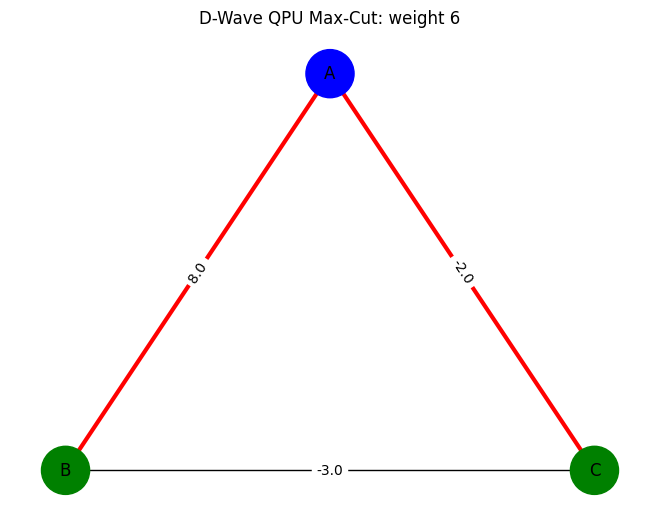

In [8]:
node_colors = ["green" if qpu_solution[v] == 0 else "blue" for v in graph.nodes]
cut_pairs = [(u, v) for u, v, _ in cut_edges]

nx.draw(graph, positions, with_labels=True, node_color=node_colors, node_size=1200)
nx.draw_networkx_edges(graph, positions, edgelist=cut_pairs, edge_color="red", width=3)
nx.draw_networkx_edge_labels(
    graph, positions, edge_labels=nx.get_edge_attributes(graph, "weight")
)
plt.title(f"D-Wave QPU Max-Cut: weight {cut_weight:g}")
plt.show()

## 8. Submit the same BQM to the hybrid solver

`LeapHybridSampler` sends the complete BQM to D-Wave's cloud-based quantum-classical hybrid service. The service manages the classical and QPU work internally, so your code does not perform minor embedding and does not request `num_reads`.

This three-variable graph is far too small to benefit from hybrid computation; this run demonstrates the API you would use for a much larger BQM. The service chooses its minimum allowed runtime automatically when `time_limit` is omitted. **This cell consumes hybrid-solver quota.**

In [ ]:
if not os.getenv("DWAVE_API_TOKEN"):
    raise RuntimeError("DWAVE_API_TOKEN is not configured; hybrid submission was not attempted.")

with LeapHybridSampler() as hybrid_sampler:
    hybrid_solver_name = hybrid_sampler.solver.name
    minimum_time = hybrid_sampler.min_time_limit(bqm)
    hybrid_sampleset = hybrid_sampler.sample(
        bqm,
        label="MaxCut QUBO hybrid tutorial",
    )

print("Hybrid solver:", hybrid_solver_name)
print("Minimum allowed runtime for this BQM (seconds):", minimum_time)
print(hybrid_sampleset)

## 9. Decode and validate the hybrid answer

The hybrid solver returns the same Ocean `SampleSet` abstraction, so decoding is almost identical to the direct-QPU result. There is no chain-break value because embedding is not exposed to the client.

In [ ]:
hybrid_best = hybrid_sampleset.first
hybrid_solution = {v: int(side) for v, side in hybrid_best.sample.items()}
hybrid_partition_0 = sorted(v for v, side in hybrid_solution.items() if side == 0)
hybrid_partition_1 = sorted(v for v, side in hybrid_solution.items() if side == 1)
hybrid_cut_edges = [
    (u, v, w) for (u, v), w in edge_dict.items()
    if hybrid_solution[u] != hybrid_solution[v]
]
hybrid_cut_weight = sum(w for _, _, w in hybrid_cut_edges)

print("Hybrid assignment:", hybrid_solution)
print("Partition 0:", hybrid_partition_0)
print("Partition 1:", hybrid_partition_1)
print("Cut edges:", hybrid_cut_edges)
print("Cut weight:", hybrid_cut_weight)
print("QUBO energy:", hybrid_best.energy)
print("Matches exact optimum:", abs(hybrid_best.energy - exact_best.energy) < 1e-9)

## What each remote solver is doing

| Step | Direct Advantage QPU | Hybrid BQM solver |
|---|---|---|
| Input | The BQM | The same BQM |
| Solver selection | Explicit Pegasus/Advantage filter | Latest accessible hybrid BQM solver |
| Embedding | `EmbeddingComposite` performs it | Managed internally by the service |
| Main control | `num_reads=100` | Optional `time_limit` in seconds |
| Execution | Direct quantum annealing samples | Managed classical and quantum computation |
| Best suited to | QPU experiments and problems that fit | Larger application-oriented BQMs |

Both are heuristic solvers: always recompute the cut weight from the returned assignment and compare with an exact solver when the instance is small enough.

## Brute force versus D-Wave QPU

| Aspect | Brute-force notebook | D-Wave QPU notebook |
|---|---|---|
| Computation | Evaluates every one of the $2^n$ binary assignments on the CPU | Quantum annealing samples low-energy states on physical quantum hardware |
| Guarantee | Exact if enumeration completes | Heuristic; the optimum is not guaranteed in a finite number of reads |
| Scaling | Runtime and memory grow exponentially with variable count | Avoids explicit enumeration, but embedding, hardware size, noise, and coefficient precision limit problems |
| Output | One deterministically selected optimum in this implementation | A SampleSet containing many answers, energies, and occurrence counts |
| Connectivity | A dense QUBO matrix is directly evaluated | Logical interactions must be minor-embedded onto physical QPU couplers; one variable may use a chain of qubits |
| Runtime for this graph | Usually extremely fast | Network, queue, programming, and embedding overhead dominate a three-variable example |
| Cost/access | Local CPU only | Requires Leap access, an API token, and available QPU quota |
| Best use here | Ground-truth validation for tiny problems | Learning the real quantum-annealing workflow and studying sampling behavior |

Both notebooks solve the same mathematical QUBO. The difference is the sampler used to search its energy landscape. For this tiny graph, brute force is the practical choice; the QPU notebook is educational rather than a performance demonstration.

## Expected optimum

The maximum signed cut weight is 6. One optimum separates A from B and C; its complement is equally optimal. The minimum QUBO energy is therefore -6.